# Dephasing and non zero temperature plots:

In [1]:
import qutip as qt
import matplotlib.pyplot as plt
import numpy as np

In [2]:
#Define variables:
theta_list = np.linspace(0,np.pi,1500)
tlist = np.linspace(0, 10, 500)

#Hilbert space dimension:
N = 2

#Constants:
w = 1
w_k = 1 #Thermal bath frequency:
T = 0.7 #temperature (K)
gamma = 1 
delta = 0.1 #Dephasing constant

#Creatrion/annihilation operator:
sigma = qt.destroy(N)
sigma_dag = sigma.dag()


#Hamiltonian:

Ham = w*sigma_dag*sigma



#Collapse operators:
N_T = 1 / (np.exp(w_k / T) - 1) #Assuming hbar, K_b = 1 

c_ops = [(np.sqrt(gamma*(N_T+1))*sigma), 
         (np.sqrt(gamma*(N_T))*sigma.dag()),
         (np.sqrt(delta)*(sigma_dag * sigma))] 



#Ground state:
ground = qt.basis(2,0) * qt.basis(2,0).dag() #Evolved state

rho_list = []

for theta in theta_list: #Independent of phi!

    x = np.sin(theta)
    y = 0
    z = np.cos(theta)

    rho = 0.5 * (
        qt.qeye(2)
        + x * qt.sigmax()
        + y * qt.sigmay()
        + z * qt.sigmaz())

    rho_list.append(rho)
    

In [3]:
#Solver:
results = []
for rh0 in rho_list:
    results.append(qt.mesolve(Ham,rh0,tlist,c_ops))

    
all_rho_t = [res.states for res in results] #Gives a list of all rho(t), for different theta.


#Calculate trace distance:
Dist = []

for rho_t in all_rho_t: #Loops over theta         
    D_t = [qt.tracedist(rho, ground) for rho in rho_t] #Loops over time
    Dist.append(D_t)

Dist = np.array(Dist)

In [4]:
#Calculate the relative strength for each pair of initial conditions:

n_theta = Dist.shape[0] #Number of theta
diff_matrix = np.zeros((n_theta, n_theta))
time_matrix = np.zeros((n_theta, n_theta))
strength_matrix = np.zeros((n_theta, n_theta))

#Calculate the initial difference in distance and time of crossing:
for i in range(n_theta):
    for j in range(i + 1, n_theta):#Skips repeated pairs of theta.
        
        diff_0 = Dist[i][0] - Dist[j][0]#Difference at t=0.
        
        diff_matrix[i,j] = diff_0
        diff_matrix[j,i] = diff_0 #Sign doesn't matter, will plot mod as some values may be negative. 
        
        #Time of crossing: 
        diff = Dist[i] - Dist[j]
        crossing_point = np.where(np.sign(diff[:-1]) != np.sign(diff[1:]))
        crossing_points = crossing_point[0]#Times where it crossed
        
        if len(crossing_points) > 0:
            first_cross = crossing_points[0]#First cross

            crossing_time = tlist[first_cross]

            time_matrix[i,j] = crossing_time
            time_matrix[j,i] = crossing_time #Again, - values shouldn't matter here 
            
            strength = diff_0 / crossing_time
            strength_matrix[i,j] = np.abs(strength)
            strength_matrix[j,i] = np.abs(strength)
            
        else:
            time_matrix[i,j] = 0
            time_matrix[j,i] = 0

            strength_matrix[i,j] = 0
            strength_matrix[j,i] = 0

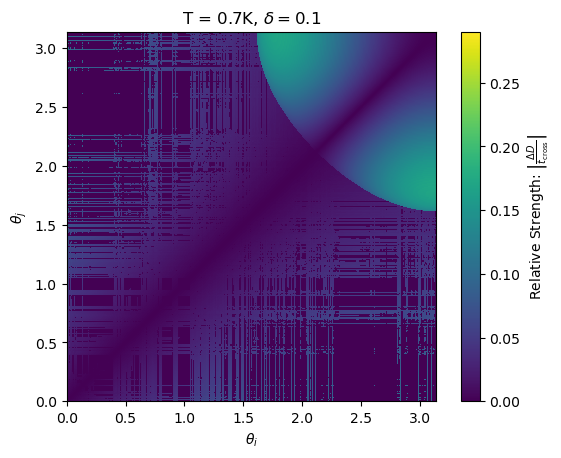

In [5]:
fig, ax = plt.subplots()


image = ax.imshow(
    strength_matrix,
    origin='lower',
    cmap="viridis",   
    interpolation='nearest',
    extent=[0, np.pi, 0, np.pi],
    vmin=0,
    vmax=0.29)

ax.set_xlabel(r"$\theta_{i}$")
ax.set_ylabel(r"$\theta_{j}$")
ax.set_title(f'T = {T}K, $\delta = {delta}$')

fig.colorbar(image, ax=ax, label=r"Relative Strength: $\left| \frac{\Delta D}{t_{\mathrm{cross}}} \right|$")

In [6]:
max_val = np.max(strength_matrix)
max_val_pos = np.argwhere(strength_matrix == max_val) #Finds where max matrix value is
#Find theta values: 
indice_1, indice_2 = max_val_pos[0][0], max_val_pos[0][1]
theta_1, theta_2 = theta_list[indice_1], theta_list[indice_2]

(1.7960939987501352, 3.141592653589793)
Largest val: max strength = 0.173
  theta_1=0.572π, theta_2=1.000π


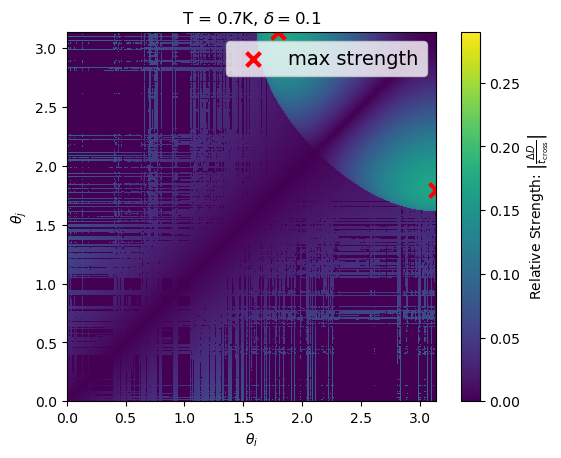

In [7]:
ax.scatter(theta_1, theta_2, color='red', s=100, marker='x',
        linewidths=3, label='max strength', zorder=2)

ax.scatter(theta_2, theta_1, color='red', s=100, marker='x',
        linewidths=3, zorder=2)
            
ax.legend(fontsize=14)

#Only print for an appreciable value of strength:
if max_val > 0.05:
        
    #Stores position/value
    #Stores all equal max points to plot
    pairs = [(theta_list[index[0]], theta_list[index[1]]) for index in max_val_pos]
    pairs = pairs[0]
    print(pairs)
    #Show data:
    print(f"Largest val: max strength = {max_val:.3f}")
    
    print(f"  theta_1={pairs[0]/np.pi:.3f}π, theta_2={pairs[1]/np.pi:.3f}π")
    
fig